In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import dendrogram, linkage

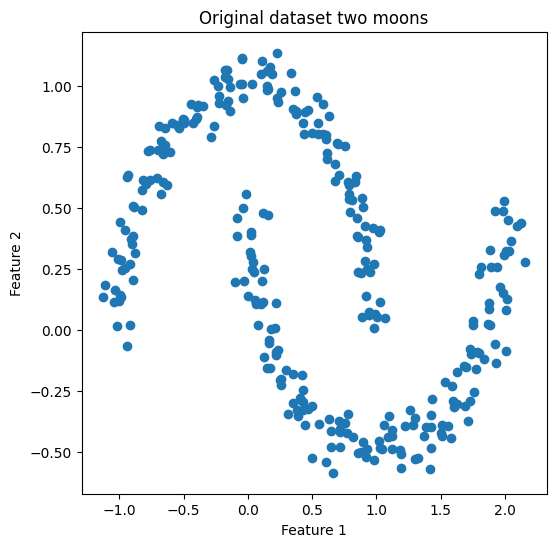

In [36]:
#dataset
X,y= make_moons(n_samples=300, noise=0.06, random_state=42)
plt.figure(figsize=(6,6))
plt.scatter(X[:,0],X[:,1])
plt.title("Original dataset two moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

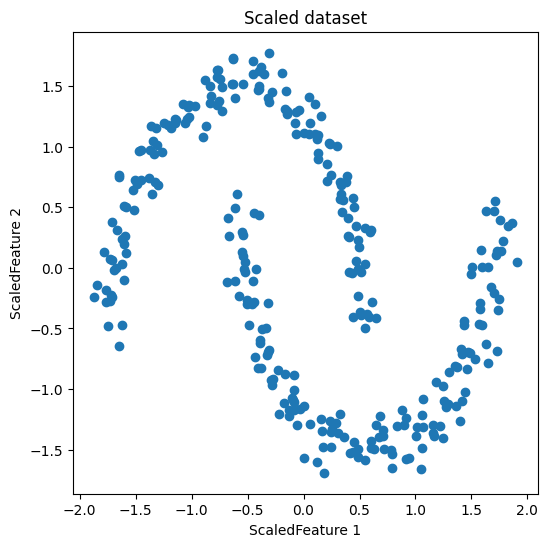

In [37]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
plt.figure(figsize=(6,6))
plt.scatter(X_scaled[:,0], X_scaled[:,1])
plt.title("Scaled dataset")
plt.xlabel("ScaledFeature 1")
plt.ylabel("ScaledFeature 2")
plt.show()

In [38]:
#DBscan implementation
dbscan=DBSCAN(eps=0.20, min_samples=3)
db_labels=dbscan.fit_predict(X_scaled)

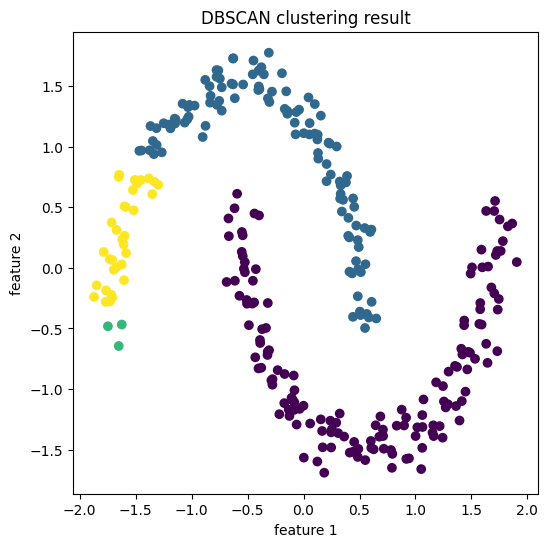

Unique cluster label: [0 1 2 3]


In [39]:
plt.figure(figsize=(6,6))
plt.scatter(X_scaled[:,0], X_scaled[:,1],c=db_labels, cmap='viridis')
plt.title("DBSCAN clustering result")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.show()
print("Unique cluster label:", np.unique(db_labels))

In [40]:
#Choosing eps k-distance Plot
neighbors=NearestNeighbors(n_neighbors=3)
neighbors_fit=neighbors.fit(X_scaled)
distances,indices=neighbors_fit.kneighbors(X_scaled)
distances=np.sort(distances[:,2])

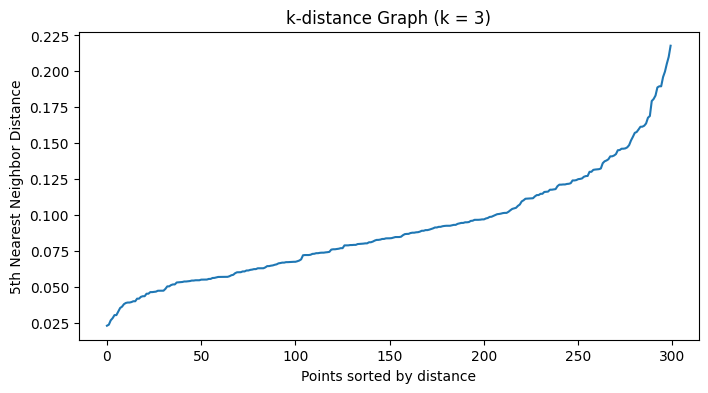

In [41]:
plt.figure(figsize=(8,4))
plt.plot(distances)
plt.title("k-distance Graph (k = 3)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()

#Hierarchical Clustering Implementation

In [42]:
#Hierarchical Clustering Implementation
hc=AgglomerativeClustering(n_clusters=6, linkage='ward')
hc_labels=hc.fit_predict(X_scaled)

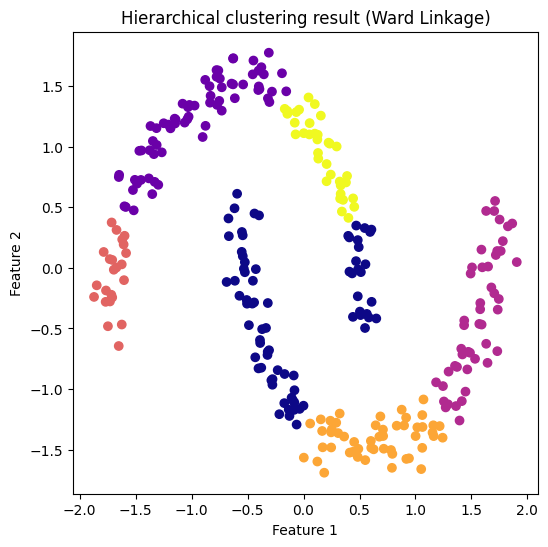

In [43]:
plt.figure(figsize=(6,6))
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=hc_labels, cmap='plasma')
plt.title("Hierarchical clustering result (Ward Linkage)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Dendrogram Construction

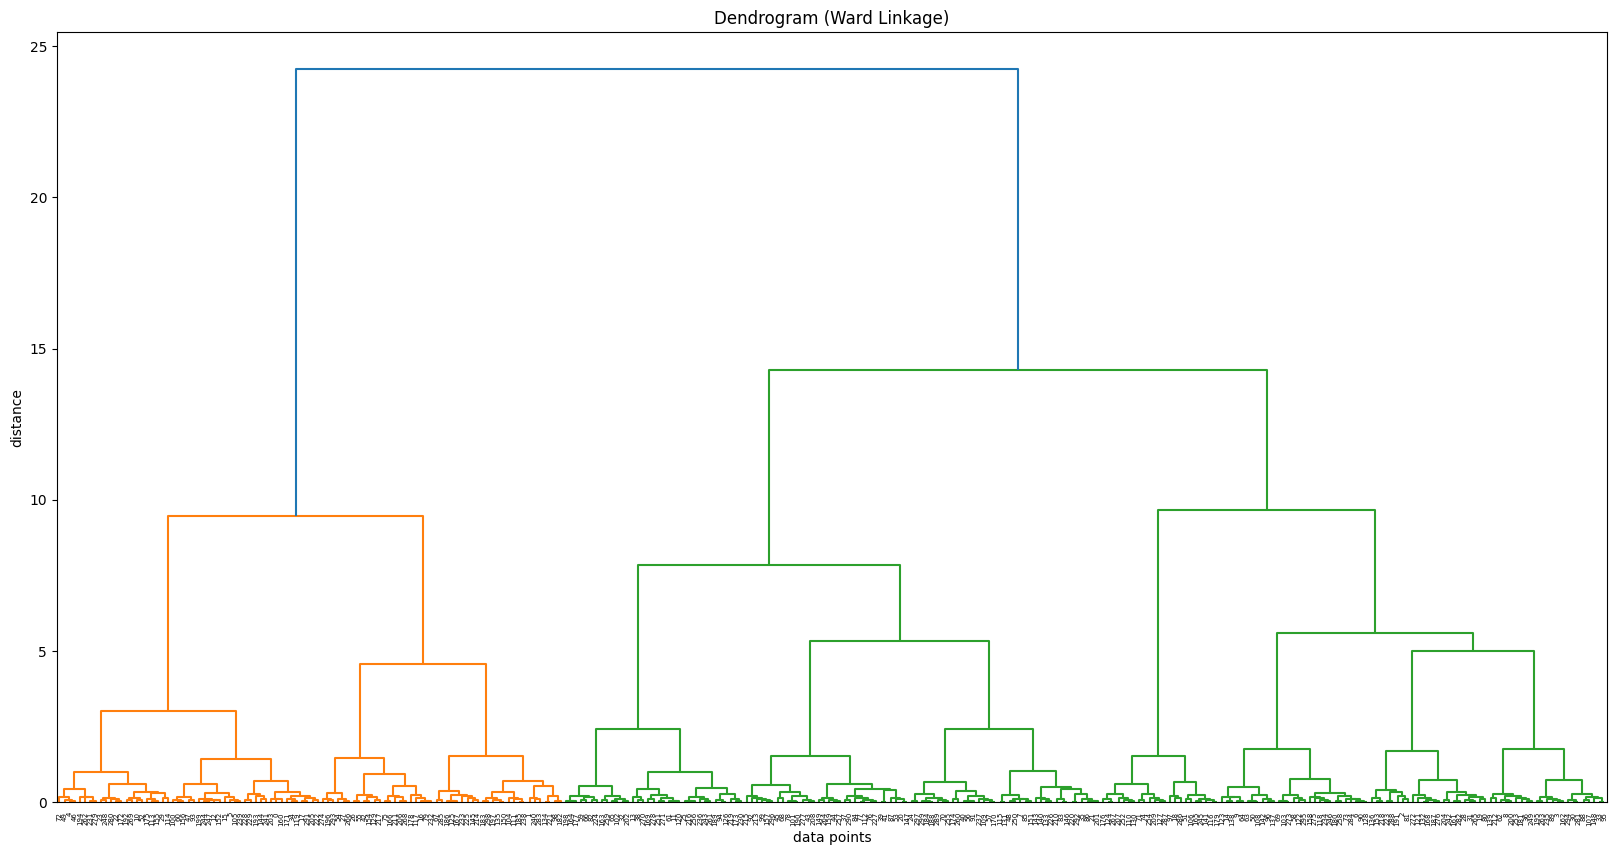

In [44]:
linked=linkage(X_scaled,method='ward')
plt.figure(figsize=(20,10))
dendrogram(linked)
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("data points")
plt.ylabel("distance")
plt.show()